In [29]:
import pandas as pd
import numpy as np

import scipy.io as sio
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

from scipy.stats import gaussian_kde

In [30]:
def getEnsembleMeanStd(tps, WhiteNoise, TimeHistory, TimePost = 0):
    ensemble = []
    for idx, ind in enumerate(tps):
        stimulus = WhiteNoise.values[int(ind*Fs-TimeHistory*Fs):int(ind*Fs + TimePost*Fs)]
        ensemble.append(stimulus)
        df = pd.DataFrame({'data': ensemble})

    # the columns are timepoints and rows each new Stimulus history
    expand = df.data.apply(pd.Series)
    if 660 in list(expand.columns):
        expand.drop([660],axis = 1, inplace = True)
    mean = expand.mean(axis = 0)
    std = expand.std(axis = 0)
    return(expand, mean, std)

In [31]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds

In [45]:
# read in the timestamps
name = 'm23_wn2'
import pickle
filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_timeStamps.pickle'
with open(filename, "rb") as f:
    testout = pickle.load(f)
all_Units_aligned = testout[0]
all_Units_prior = testout[1]
WhiteNoise = testout[2]

<Figure size 640x480 with 0 Axes>

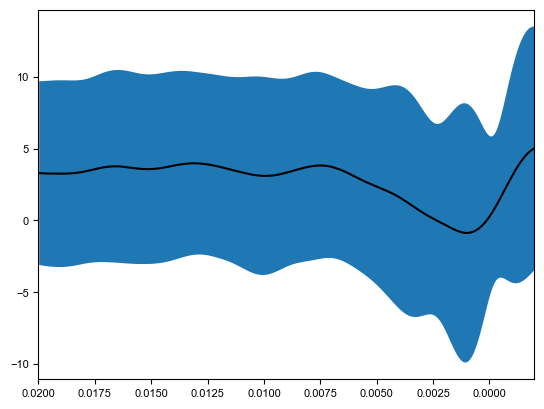

<Figure size 640x480 with 0 Axes>

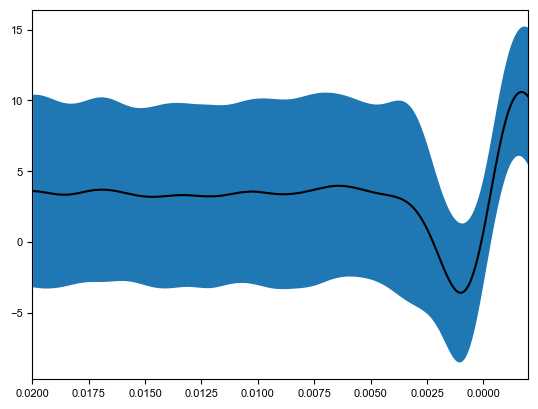

<Figure size 640x480 with 0 Axes>

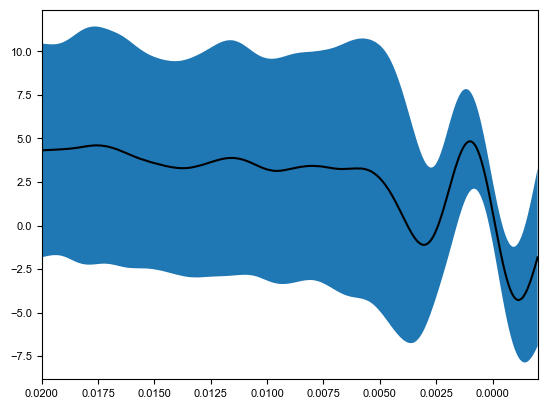

In [33]:
# get the sta and ste
ste = {}
sta = {}
sta_error = {}
for k in all_Units_aligned.keys():
    unit_tp = np.concatenate(all_Units_aligned[k], axis = 0)
    ste[k], sta[k], sta_error[k] = getEnsembleMeanStd(unit_tp, WhiteNoise, TimeHistory, TimePost)
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)
    f = plt.figure()
    plt.plot(time_axis, np.flip(sta[k]), 'k')
    plt.fill_between(time_axis
                     , np.flip(sta[k]-sta_error[k]), np.flip(sta[k]+sta_error[k]))
    plt.xlim(0.02, -0.002)
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_STA.pdf'
    plt.savefig(filename)
    plt.show()
    plt.clf()

<Figure size 640x480 with 0 Axes>

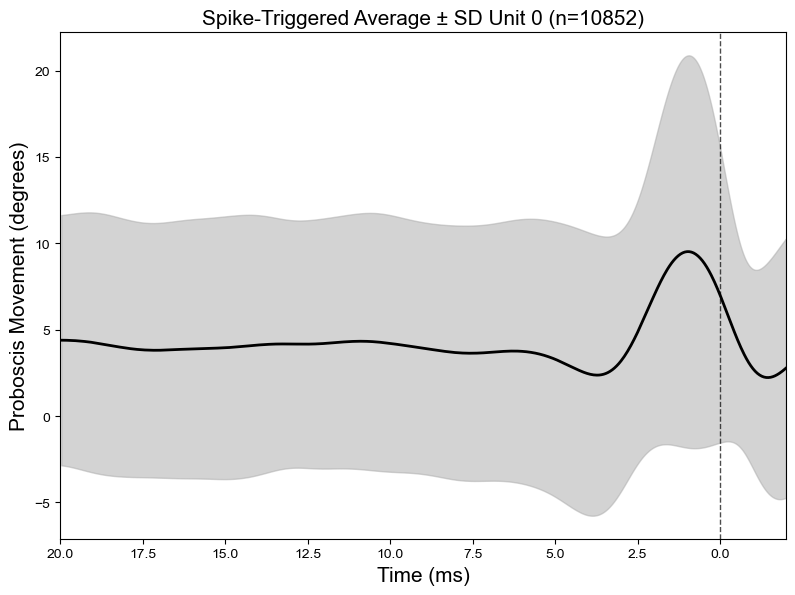

Saved STA: m23_wn2_unit_0_STA.csv


<Figure size 640x480 with 0 Axes>

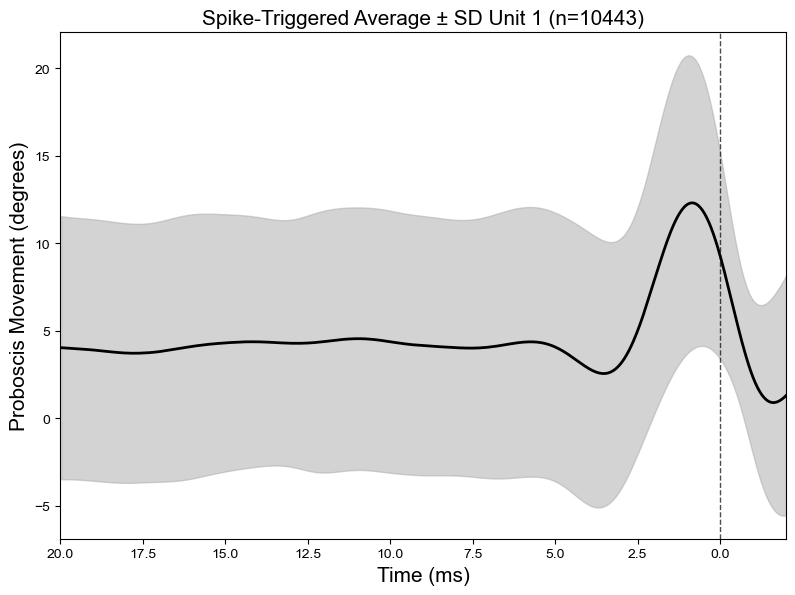

Saved STA: m23_wn2_unit_1_STA.csv


<Figure size 640x480 with 0 Axes>

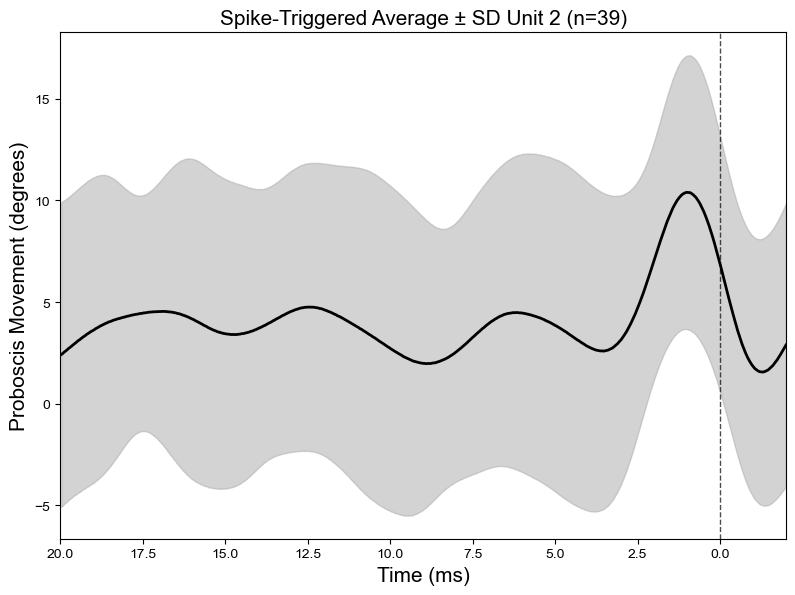

Saved STA: m23_wn2_unit_2_STA.csv


In [46]:
# get the sta and ste
ste = {}
sta = {}
sta_error = {}
for k in all_Units_aligned.keys():
    unit_tp = np.concatenate(all_Units_aligned[k], axis = 0)
    ste[k], sta[k], sta_error[k] = getEnsembleMeanStd(unit_tp, WhiteNoise, TimeHistory, TimePost)
    
    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)
    t_ms = time_axis * 1000  # convert to ms for x axis
    n_spikes = len(unit_tp)
    unit_label = k.replace('unit_', 'Unit ')
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.fill_between(t_ms, np.flip(sta[k]-sta_error[k]), np.flip(sta[k]+sta_error[k]),
                    color='darkgrey', alpha=0.5)
    ax.plot(t_ms, np.flip(sta[k]), 'k', linewidth=2, label='Mean (STA)')
    ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax.set_xlim(20, -2)  # ms, reversed as original
    ax.set_xlabel('Time (ms)', fontsize=15)
    ax.set_ylabel('Proboscis Movement (degrees)', fontsize=15)
    ax.set_title(f'Spike-Triggered Average ± SD {unit_label} (n={n_spikes})', fontsize=15)
    ax.tick_params(labelsize=10)
    plt.tight_layout()
    
    filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_STA.pdf'
    plt.savefig(filename)
    plt.show()
    plt.clf()
    
    # save STA values
    sta_df = pd.DataFrame({'time_ms': t_ms, 'sta_mean': np.flip(sta[k]), 'sta_std': np.flip(sta_error[k])})
    sta_df.to_csv('/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_STA.csv', index=False)
    print(f'Saved STA: {name}_{k}_STA.csv')

In [51]:
print(f'sta_vec range: {sta_vec.min():.4f} to {sta_vec.max():.4f}')
print(f'sta_vec mean: {np.mean(sta_vec):.4f}')
print(f'ste segment example range: {ste[k].iloc[0].min():.4f} to {ste[k].iloc[0].max():.4f}')

sta_vec range: -1.7346 to 3.3352
sta_vec mean: 0.0000
ste segment example range: -16.6490 to 11.4439


<Figure size 640x480 with 0 Axes>

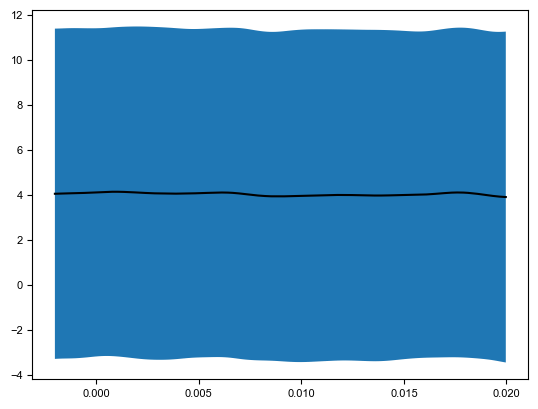

<Figure size 640x480 with 0 Axes>

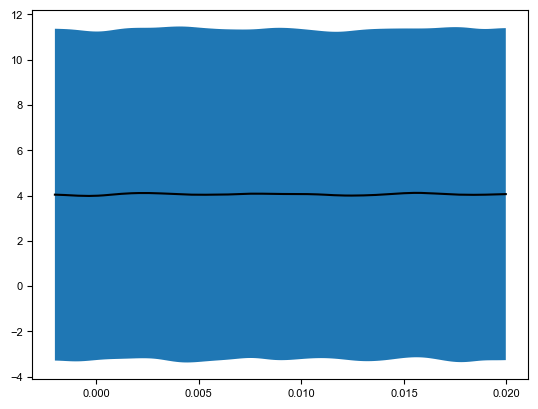

<Figure size 640x480 with 0 Axes>

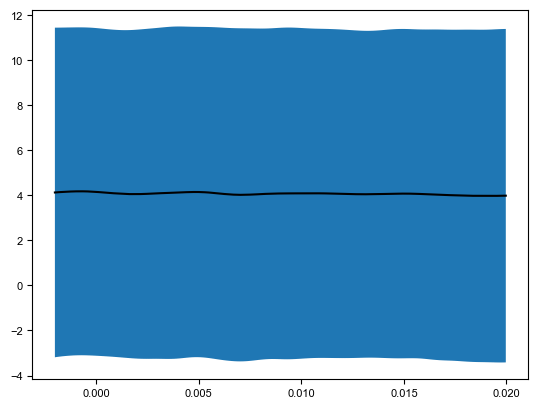

In [47]:
prior_ensemble = {}
prior_mean = {}
prior_error = {}
for k in all_Units_prior.keys():
    unit_tp = np.concatenate(all_Units_prior[k], axis = 0)
    prior_ensemble[k], prior_mean[k], prior_error[k] = getEnsembleMeanStd(unit_tp, WhiteNoise, TimeHistory, TimePost)
    

    time_axis = np.arange(-TimePost, TimeHistory, 1/Fs)

    prior_df = pd.DataFrame({
    'time_ms': np.flip(time_axis) * 1000,
    'mean': np.flip(prior_mean[k].values),
    'std': np.flip(prior_error[k].values)})
    prior_df.to_csv(f'/Users/meghnaanand/Desktop/Analysis/{name}_{k}_prior.csv', index=False)
    
    f = plt.figure()
    plt.plot(time_axis, np.flip(prior_mean[k]), 'k')

    plt.fill_between(time_axis
                     , np.flip(prior_mean[k]-prior_error[k])
                     , np.flip(prior_mean[k]+prior_error[k]))
    #plt.xlim(0.02, -0.002)
    #filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_prior.pdf'
    #plt.savefig(filename)
    plt.show()
    plt.clf()

In [50]:
nld = {}
bins = {}

for k in ste.keys():
    if k == 'unit_0':
        continue
    
    f, ax = plt.subplots(1, 2, figsize=(10, 5))  # moved inside loop
    
    num_spikeEvents = len(ste[k])
    num_priorEvents = len(prior_ensemble[k])
    
    sta_vec = sta[k][0:600-int(TimePost*Fs)]
    sta_vec = sta_vec - np.mean(sta_vec)
    projected_ste = np.dot(ste[k].iloc[:,0:600-int(TimePost*Fs)], sta_vec)
    projected_prior = np.dot(prior_ensemble[k].iloc[:,0:600-int(TimePost*Fs)], sta_vec)
    prior_std = np.std(projected_prior)
    print(f'{k} projected_prior range: {projected_prior.min():.4f} to {projected_prior.max():.4f}')
    print(f'{k} projected_ste range: {projected_ste.min():.4f} to {projected_ste.max():.4f}')
    
    # save CSV
    pd.DataFrame({'prior_std': [prior_std]}).to_csv(
        f'/Users/meghnaanand/Desktop/Analysis/{name}_{k}_prior_std.csv', index=False)
    projected_ste = projected_ste / prior_std
    projected_prior = projected_prior / prior_std
    
    values, bins[k], _ = ax[0].hist([projected_ste, projected_prior], bins=30, density=True)
    
    with np.errstate(invalid='ignore', divide='ignore'):
        nld[k] = np.where(values[1] > 0, values[0] / values[1], np.nan)
    
    ax[1].plot(bins[k][:-1], nld[k], 'o-', color='black')
    ax[1].set_xlabel('STA-Stimulus Similarity', fontsize=15)
    ax[1].set_ylabel('Probability of Firing', fontsize=15)

    
    # save CSV
    #nld_df = pd.DataFrame({'bins': bins[k][:-1], 'nld': nld[k]})
    #nld_df.to_csv(f'/Users/meghnaanand/Desktop/Analysis/{name}_{k}_NLD.csv', index=False)
    #print(f'Saved NLD: {name}_{k}_scaledNLD.csv')
    
    # save figure
    #filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_NLD.pdf'
    #plt.savefig(filename)
    #plt.show()
    #plt.clf()

unit_1 projected_prior range: -1666.1348 to 1928.8947
unit_1 projected_ste range: -1374.8587 to 1928.4424
unit_2 projected_prior range: -3462.7559 to 3114.6903
unit_2 projected_ste range: -1036.5668 to 1856.2714


In [ ]:
# ORIGINAL UNSCALED NLD CODE - use this for unscaled stimulus data
# # generate the Non-Linear Decision (NLD) functions
# # projection for ste
# nld = {}
# bins = {}
# f, ax = plt.subplots(1,2, figsize=(10, 5))
# for k in ste.keys():
# #     k = 'unit_3'
#     if k == 'unit_0':
#         continue
#     num_spikeEvents = len(ste[k])
#     num_priorEvents = len(prior_ensemble[k])
    
#     projected_ste = np.dot(ste[k].iloc[:,0:600-int(TimePost*Fs)], sta[k][0:600-int(TimePost*Fs)])
#     projected_prior = np.dot(prior_ensemble[k].iloc[:,0:600-int(TimePost*Fs)], sta[k][0:600-int(TimePost*Fs)])
#     values, bins[k], _ = ax[0].hist([projected_ste, projected_prior], bins = 30, density = True)
#     nld[k] = values[0]/values[1]
#     ax[1].plot(bins[k][:-1], nld[k], 'o-', color='black')
#     nld_df = pd.DataFrame({
#     'bins': bins[k][:-1],
#     'nld': nld[k]})
#     nld_df.to_csv(f'/Users/meghnaanand/Desktop/Analysis/{name}_{k}_NLD.csv', index=False)
#     ax[1].set_xlabel('STA-Stimulus Similarity', fontsize=15)
#     ax[1].set_ylabel('Probability of Firing', fontsize=15)
#     filename = '/Users/meghnaanand/Desktop/Analysis/' + name + '_' + k + '_NLD.pdf'
#     plt.savefig(filename)
#     ax[0].cla()
#     ax[1].cla()

In [ ]:
# # plot a specific nld

# k = 'unit_2'
# num_spikeEvents = len(ste[k])
# plt.plot(bins[k][:-1], final[k])
# plt.savefig('./dataFolder/m7_unit3_nld.pdf')

In [ ]:
# # eigen values
# normalized_st = {}
# st_norm = {}
# k = 'unit_2'
# normalized_st[k] = ste[k].loc[0:600-int(TimePost*Fs)] - sta[k].loc[0:600-int(TimePost*Fs)]
# st_norm[k] = normalized_st[k].loc[:,0:600-int(TimePost*Fs)]
# # normalized_prior[k] = ste[k].loc[0:600-int(TimePost*Fs)] - sta[k].loc[0:600-int(TimePost*Fs)]
# # st_norm[k] = normalized_st[k].loc[:,0:600-int(TimePost*Fs)]
# # for row, s_i in st_norm[k].iterrows():
# cov_st = np.cov(st_norm[k])
# cov_prior = np.cov(prior_ensemble[k].loc[0:cov_st.shape[1]-1, :])

In [ ]:
#from scipy import linalg

#s ={}
#vh ={}

for k in ste.keys():
    rows = np.unique(np.where(np.isnan(ste[k]))[0]) #remove stuff with NaNs
    spike_triggered = ste[k].drop(rows, axis = 0)
    cov_st = np.cov(np.transpose(spike_triggered), bias = True)

    rows = np.unique(np.where(np.isnan(prior_ensemble[k]))[0])
    prior = prior_ensemble[k].drop(rows, axis = 0)
    cov_prior = np.cov(np.transpose(prior), bias = True)

    # plot the covariance matrices
    f = plt.figure() # plot covariance matrix
    xmin = 0
    ymin = 0
    dx = 0.25
    dy = 1

    vmin = np.min([cov_st, cov_prior])
    vmax = np.max([cov_st, cov_prior])
    
    ax0 = f.add_axes([xmin, ymin, dx, dy])
    z1 = ax0.imshow(cov_st, vmin = vmin, vmax = vmax)
    ax0.invert_yaxis()
    plt.colorbar(z1, fraction=0.046, pad=0.04)

    ax1 = f.add_axes([xmin + dx + 0.05, ymin, dx, dy])
    z2 = ax1.imshow(cov_prior, vmin = vmin, vmax = vmax)
    ax1.invert_yaxis()
    plt.colorbar(z2, fraction=0.046, pad=0.04)
    ax1.set_yticks([])

    ax2 = f.add_axes([xmin + 2*dx + 2*0.05, ymin, dx, dy])
    z3 = ax2.imshow(cov_st - cov_prior)
    ax2.invert_yaxis()
    ax2.set_yticks([])
    plt.colorbar(z3, fraction=0.046, pad=0.04)

    filename = './dataFolder/' + name + '_' + k + '_covarianceMatrix.pdf'
    plt.savefig(filename)

    plt.clf()

    # do svd and the biggest eigenmodes
    U, s_, vh_ = linalg.svd(cov_st - cov_prior)
    s[k] = s_
    vh[k] = vh_
    
    # plot eigen values
    f1 = plt.figure() # plot eigenvalues
    plt.plot(s_[0:10]**2, 'o-')
    filename = './dataFolder/' + name + '_' + k + '_EigenValues.pdf'
    plt.savefig(filename)
    plt.clf()

    # plot eigen vectors
    f2, ax = plt.subplots(5,2, figsize = (10,6)) # plot eigenvectors
    ax = ax.ravel()
    for idx, axes in enumerate(ax):
        time_ax = np.arange(0, len(vh_[idx]))*1/Fs
        ax[idx].plot(time_ax, np.flip(vh_[idx]))
        ax[idx].set_xlim(0.02, -0.002)
    filename = './dataFolder/' + name + '_' + k + '_EigenVectors.pdf'
    plt.savefig(filename)
    for axes in ax:
        axes.cla()

In [ ]:
# pickle dump the timestamps
#import pickle

#saveObject = (ste, prior_ensemble, nld, bins, s, vh)
#with open("./dataFolder/" + name + "_EncodingModel.pickle","wb") as f:
    #pickle.dump(saveObject, f)